>> Za pogodno izabranu MTP funkciju _f : (0,c) -> R_ dokazati MTP nejednakost _f(x) > 0_ nad _(0,c)_, određujuci pozitivnu nanižnu polinomsku aproksimaciju _P(x) > 0_ nad _(0,c)_.

Za prvi dio zadatka, koristeći metodu diretnog poređenja, kao primjer ćemo koristiti narednu funkciju na intervalu _(0, pi/2 ≈ 1.57)_.

In [81]:
from math import sin, cos, pow, pi

a, b = 0, round(pi/2, 3)
def f(x: float) -> float:
	return pow(x, 3) * sin(x) - x * pow(cos(x), 3) + x - 3/2 * pow(x, 3) + 3/32 * pow(x, 4)

Umjesto _sin(x)_ ćemo koristiti odgovarajući Tejlorov razvoj (izraz _T<sub>4k<sub>1</sub>+3</sub><sup>sin,0</sup>_), koji je strogo manji od _sin(x)_. A umjesto _cos(x)_ ćemo takođe koristiti njegov Tejlorov razvoj (izraz _T<sub>4k<sub>2</sub>+0</sub><sup>cos,0</sup>_), koji je strogo veći od _cos(x)_.

Zbog toga je potrebno napisati pomoćne funkcije koje će kreirati odgovarajuće Tejlorove polinome, i koje ćemo kasnije ubacitvati u osnovni polinom.

In [82]:
from numpy.polynomial.polynomial import Polynomial
from math import factorial

def generate_sin_term_4k_3(k: int, factor: int = 1) -> Polynomial:
	coef: list[float] = []
	for i in range(0, 2*k+2):
		sign = pow(-1, i)
		denominator = factorial(2*i+1)

		coef.append(0)
		coef.append(sign / denominator * factor ** (2*i + 1))

	return Polynomial(coef if coef else [0])

def generate_cos_term_4k_0(k: int, factor: int = 1) -> Polynomial:
	coef: list[float] = []
	for i in range(0, 2*k+1):
		sign = pow(-1, i)
		denominator = factorial(2*i)

		coef.append(sign / denominator * factor ** (2*i))
		coef.append(0)

	return Polynomial(coef if coef else [0])

def generate_cos_term_4k_2(k: int, factor: int = 1) -> Polynomial:
	coef: list[float] = []
	for i in range(0, 2*k+2):
		sign = pow(-1, i)
		denominator = factorial(2*i)

		coef.append(sign / denominator * factor ** (2*i))
		coef.append(0)

	return Polynomial(coef if coef else [0])

U oba izraza postoji po jedno _k_, koje biramo tako da polinom bude pozitivan na čitavom datom intervalu. Zbog toga je potrebno iskoristiti funkcije iz prethodnog zadatka, kako bismo utvrdili znak polinoma.

In [83]:
def is_positive(p: Polynomial, scope: tuple[float, float]) -> bool:
	a, b = scope

	def generate_sturms_chain(p: Polynomial):
		chain = [p, p.deriv()]

		while chain[-1].degree() > 0:
			chain.append(-(chain[-2] % chain[-1]))

		return chain

	def sign_changes(chain: list[Polynomial], x: float):
		values = [p(x) for p in chain]

		changes = 0
		for i in range(1, len(values)):
			if values[i] * values[i - 1] < 0:
				changes += 1

		return changes

	def calculate_number_of_zeroes(p: Polynomial, scope: tuple[float, float]):
		a, b = scope
		chain = generate_sturms_chain(p)

		return sign_changes(chain, a) - sign_changes(chain, b)

	allowed_zeros = 0
	if p(a) == 0:
		a -= 0.1
		allowed_zeros += 1
	if p(b) == 0:
		b += 0.1
		allowed_zeros += 1

	zeros = calculate_number_of_zeroes(p, (a, b))
	always_positive = zeros == allowed_zeros and p((a+b)/2) > 0

	return always_positive

Sada možemo napisati više ugnježdenih petlji pomoću kojih tražimo odgovarajuću kombinaciju oba _k_. Pretražujemo prostor dok ne nađemo prvi polinom koji zadovoljava uslov pozitivnosti.

Funkcija _generate_polynomial_ kreira rezultujući polinom tako što ubacuje odgovarajuće Tejlorove polinome u ostatak.

In [84]:
from itertools import count

def generate_polynomial(sin_part: Polynomial, cos_part: Polynomial) -> Polynomial:
	return Polynomial([0, 0, 0, 1]) * sin_part - Polynomial([0, 1, 0, 0]) * cos_part ** 3 + Polynomial([0, 1, 0, -3/2, 3/32])

class ResultFoundError(Exception):
	pass

polynomials: dict[tuple[int, int], Polynomial] = {}
try:
	for k1 in count():
		sin_part = generate_sin_term_4k_3(k1)
		for k2 in range(0, k1 + 1):
			cos_part = generate_cos_term_4k_0(k2)
			polynomial = generate_polynomial(sin_part, cos_part)
			polynomials[(k1, k2)] = polynomial
			print(f"k1={k1}, k2={k2}\n\t{polynomial}", end='\n\n')

			if is_positive(polynomial, (a, b)):
				raise ResultFoundError()
except ResultFoundError:
	pass

print(f"Pronađen polinom za k1={k1}, k2={k2}\n\t{polynomial}")

k1=0, k2=0
	0.0 + 0.0 x + 0.0 x**2 - 1.5 x**3 + 1.09375 x**4 + 0.0 x**5 -
0.16666667 x**6

k1=1, k2=0
	0.0 + 0.0 x + 0.0 x**2 - 1.5 x**3 + 1.09375 x**4 + 0.0 x**5 -
0.16666667 x**6 + 0.0 x**7 + 0.00833333 x**8 + 0.0 x**9 - 0.00019841 x**10

k1=1, k2=1
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 + 1.09375 x**4 - 0.875 x**5 -
0.16666667 x**6 + 0.25 x**7 + 0.00833333 x**8 - 0.03645833 x**9 -
0.00019841 x**10 + 0.00260417 x**11 + -0.0 x**12 - (7.2337963e-05) x**13

Pronađen polinom za k1=1, k2=1
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 + 1.09375 x**4 - 0.875 x**5 -
0.16666667 x**6 + 0.25 x**7 + 0.00833333 x**8 - 0.03645833 x**9 -
0.00019841 x**10 + 0.00260417 x**11 + -0.0 x**12 - (7.2337963e-05) x**13


A sada mozemo i da iscrtamo sve aproksimacije koje smo probali, kao i originalnu funkciju.

Iz datog grafika vidimo da su prve dvije aproksimacije brzo otišle prema negativnim vrijednostima, dok je poslednja aproksimacija jako dobro ispratila originalnu funkciju.

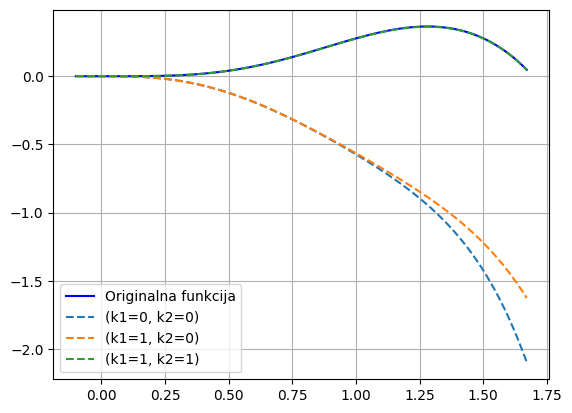

In [85]:
import matplotlib.pyplot as plt
from numpy import linspace

x_dots = linspace(a-0.1, b+0.1, 100)
plt.plot(x_dots, [f(x) for x in x_dots], color='blue', label='Originalna funkcija')
for (k1, k2), p in polynomials.items():
	plt.plot(x_dots, p(x_dots), label=f"(k1={k1}, k2={k2})", linestyle='dashed')

plt.legend()
plt.grid(True)
plt.show()

Za drugi dio zadatka koristi se metoda višestrukih uglova nad narednom funkcijom (interval ostaje isti). 

In [86]:
def f(x: float) -> float:
	return cos(x) * pow(sin(x), 2) + x * sin(x) - 2 * pow(x, 2) * cos(x)

Nakon transformacije prvog sabirka u MTP-u, dobijamo izraz sa 4 trigonometrijske funkcije. Zbog toga formirani polinom ima 4 koeficijenta (_k_) kroz koje prolazim. Takođe, i ovdje tražimo polinom koji je pozitivan na čitavom intervalu.

In [87]:
from itertools import count

def generate_polynomial(
	cos_part_1: Polynomial, 
	cos_part_2: Polynomial, 
	sin_part: Polynomial,
	cos_part_3: Polynomial) -> Polynomial:
	return -1/4 * cos_part_1 + 1/4 * cos_part_2 + Polynomial([0, 1]) * sin_part - Polynomial([0, 0, 2]) * cos_part_3

try:
	for k1 in count():
		cos_part_1 = generate_cos_term_4k_0(k1, 3)
		for k2 in range(0, k1 + 1):
			cos_part_2 = generate_cos_term_4k_2(k2)
			for k3 in range(0, k2 + 1):
				sin_part = generate_sin_term_4k_3(k3)
				for k4 in range(0, k3 + 1):
					cos_part_3 = generate_cos_term_4k_0(k4)
					polynomial = generate_polynomial(cos_part_1, cos_part_2, sin_part, cos_part_3)
					print(f"k1={k1}, k2={k2}, k3={k3}, k4={k4}\n\t{polynomial}", end='\n\n')

					if is_positive(polynomial, (a, b)):
						raise ResultFoundError()
except ResultFoundError:
	pass

print(f"Pronađen polinom za k1={k1}, k2={k2}, k3={k3}, k4={k4}\n\t{polynomial}")

k1=0, k2=0, k3=0, k4=0
	0.0 + 0.0 x - 1.125 x**2 + 0.0 x**3 - 0.16666667 x**4

k1=1, k2=0, k3=0, k4=0
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 - 1.01041667 x**4

k1=1, k2=1, k3=0, k4=0
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 - 1.0 x**4 + 0.0 x**5 - 0.00034722 x**6

k1=1, k2=1, k3=1, k4=0
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 - 1.0 x**4 + 0.0 x**5 +
0.00798611 x**6 + 0.0 x**7 - 0.00019841 x**8

k1=1, k2=1, k3=1, k4=1
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 + 0.0 x**4 + 0.0 x**5 -
0.07534722 x**6 + 0.0 x**7 - 0.00019841 x**8

k1=2, k2=0, k3=0, k4=0
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 - 1.01041667 x**4 + 0.0 x**5 +
0.253125 x**6 + 0.0 x**7 - 0.0406808 x**8

k1=2, k2=1, k3=0, k4=0
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 - 1.0 x**4 + 0.0 x**5 +
0.25277778 x**6 + 0.0 x**7 - 0.0406808 x**8

k1=2, k2=1, k3=1, k4=0
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 - 1.0 x**4 + 0.0 x**5 +
0.26111111 x**6 + 0.0 x**7 - 0.04087922 x**8

k1=2, k2=1, k3=1, k4=1
	0.0 + 0.0 x + 0.0 x**2 + 0.0 x**3 + 0.0 x**4 + 0.0 x**5 +
0.17777778 x**6 + 0.

Sada možemo iscrati najbolju aproksimaciju, kao i stvarnu funkciju.

Vidimo da je funkcija tokom čitavog intervala pozitivna (što je očekivano), kao i da prati oblik originalne funkcije.

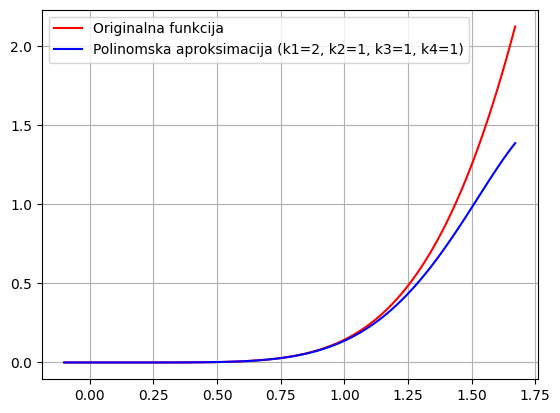

In [88]:
plt.plot(x_dots, [f(x) for x in x_dots], color='red', label='Originalna funkcija')
plt.plot(x_dots, polynomial(x_dots), color='blue', label=f'Polinomska aproksimacija (k1={k1}, k2={k2}, k3={k3}, k4={k4})')
plt.legend()
plt.grid(True)
plt.show()